# Heart Disease Risk Modelling — Phase 1: EDA and Classical Models
**Advanced Machine Learning · Project 15** &nbsp;|&nbsp; Bayesian networks, Naive Bayes and classical baselines on the UCI Cleveland data

| Student | Enrollment no. |
|---|---|
| Aaryan Yadav | 2401010011 |
| Shivam Mishra | 2401010442 |
| Satyam Kumar | 2401010429 |
| Himank Kaushik | 2401010187 |
| Mohammed Yaseen | 2401010281 |

> **Scope.** This notebook is **Phase 1 (Advanced ML)**: exploratory data analysis, leak-free preprocessing, documented discretisation, a hand-specified Bayesian network (pgmpy), Naive Bayes, and classical reference models, all compared with repeated stratified cross-validation (ROC AUC, PR AUC, sensitivity, specificity, calibration). The regularised MLP and SHAP comparison belong to **Phase 2 (Deep Learning)** and are intentionally not included here.
>
> **Disclaimer.** This is a prediction exercise on a historical research dataset, *not* clinical decision support. Predicted risks must not be read as medical recommendations.

**Notebook map:** 1 Data & target · 2 EDA · 3 Preprocessing & discretisation · 4 Models · 5 Evaluation protocol · 6 Results · 7 Ablations & sensitivity · 8 Interpreting the Bayesian network · 9 Findings, gap analysis, limitations, hand-off to Phase 2

In [1]:
%matplotlib inline
import sys, time, warnings; warnings.filterwarnings("ignore", category=FutureWarning, module="pgmpy"); sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, networkx as nx
from pathlib import Path
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, mutual_info_score
from data import *; from bayes import *; from classical import *; from evaluate import *; from metrics import *
RES = Path("../results"); FIG = RES / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED, K, R, B = 2026, 5, 5, 500
POS, NEG, BLUE, AMBER, GREY = "#e63946", "#2a9d8f", "#2a6f97", "#d98e04", "#6c757d"
def save(name): plt.tight_layout(); plt.savefig(FIG / name, dpi=150); plt.show()

## 1. Data and target definition
Source: UCI Heart Disease repository, **processed Cleveland** file (`data/processed.cleveland.data`, SHA-256 `a74b7efa…27c8`). 303 patients, 13 predictors and the 0–4 angiographic label `num`.

In [2]:
df = load()
schema = pd.DataFrame({"variable": FEATURES, "type": ["numeric"]*5 + ["categorical"]*8, "meaning": [
 "age in years", "resting blood pressure (mmHg)", "serum cholesterol (mg/dl)", "maximum heart rate achieved (bpm)", "exercise-induced ST depression (mm)",
 "sex (1 = male, 0 = female)", "chest pain type (1 typical angina, 2 atypical, 3 non-anginal, 4 asymptomatic)", "fasting blood sugar > 120 mg/dl (1 = yes)",
 "resting ECG (0 normal, 1 ST-T abnormality, 2 LV hypertrophy)", "exercise-induced angina (1 = yes)", "slope of peak-exercise ST segment (1 up, 2 flat, 3 down)",
 "major vessels coloured by fluoroscopy (0–3)", "thallium scan (3 normal, 6 fixed defect, 7 reversible defect)"]})
display(schema)
print("Target definition: y = 1 if num >= 1 (angiographic narrowing > 50% in any major vessel), else 0")
print(df["num"].value_counts().sort_index().to_dict(), "->", df["target"].value_counts().sort_index().to_dict(), f"(prevalence {df.target.mean():.3f})")
miss = df[FEATURES].isna().sum(); print("Missing values:", miss[miss > 0].to_dict(), "| rows affected:", int(df[FEATURES].isna().any(axis=1).sum()))
df.head()

,variable,type,meaning
0,age,numeric,age in years
1,trestbps,numeric,resting blood pressure (mmHg)
2,chol,numeric,serum cholesterol (mg/dl)
3,thalach,numeric,maximum heart rate achieved (bpm)
4,oldpeak,numeric,exercise-induced ST depression (mm)
5,sex,categorical,"sex (1 = male, 0 = female)"
6,cp,categorical,"chest pain type (1 typical angina, 2 atypical,..."
7,fbs,categorical,fasting blood sugar > 120 mg/dl (1 = yes)
8,restecg,categorical,"resting ECG (0 normal, 1 ST-T abnormality, 2 L..."
9,exang,categorical,exercise-induced angina (1 = yes)


Target definition: y = 1 if num >= 1 (angiographic narrowing > 50% in any major vessel), else 0
{0: 164, 1: 55, 2: 36, 3: 35, 4: 13} -> {0: 164, 1: 139} (prevalence 0.459)
Missing values: {'ca': 4, 'thal': 2} | rows affected: 6


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0


**Missingness and row independence.** `ca` has 4 missing values and `thal` has 2, across 6 rows. The Bayesian estimator uses locally available node/parent counts (not EM); missing evidence is marginalised at prediction. Other models impute within each training fold. There are no exact duplicate predictor rows. The processed file has no usable patient identifiers, so one-row-per-patient independence is an assumption, not independently verified.

## 2. Exploratory data analysis

### 2.1 Class balance and sex

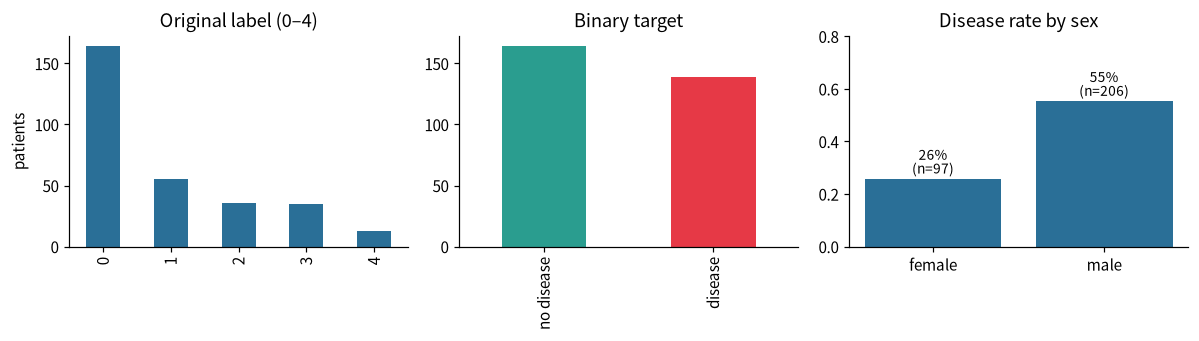

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
df["num"].value_counts().sort_index().plot.bar(ax=ax[0], color=BLUE); ax[0].set(title="Original label (0–4)", xlabel="", ylabel="patients")
df["target"].map({0: "no disease", 1: "disease"}).value_counts().plot.bar(ax=ax[1], color=[NEG, POS]); ax[1].set(title="Binary target", xlabel="")
r = df.groupby("sex").target.agg(["mean", "size"]); ax[2].bar(["female", "male"], r["mean"], color=BLUE)
for i, (m, n) in enumerate(zip(r["mean"], r["size"])): ax[2].text(i, m + .02, f"{m:.0%}\n(n={n})", ha="center", fontsize=9)
ax[2].set(title="Disease rate by sex", ylim=(0, .8)); save("fig_eda_balance.png")

### 2.2 Numeric variables by outcome

age       trestbps           chol        thalach        oldpeak      
         mean   std     mean    std    mean    std    mean    std    mean   std
target                                                                         
0       52.59  9.51   129.25  16.20  242.64  53.46  158.38  19.20    0.59  0.78
1       56.63  7.94   134.57  18.77  251.47  49.49  139.26  22.59    1.57  1.30

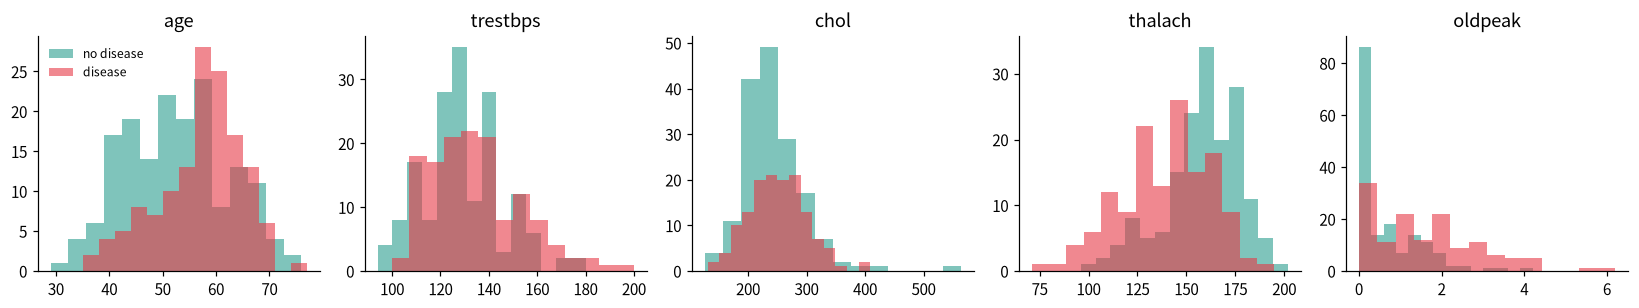

In [4]:
display(df.groupby("target")[NUM].agg(["mean", "std"]).round(2))
fig, ax = plt.subplots(1, 5, figsize=(15, 2.9))
for a, v in zip(ax, NUM):
    for t, c, l in [(0, NEG, "no disease"), (1, POS, "disease")]: a.hist(df[v][df.target == t], bins=14, alpha=.6, color=c, label=l)
    a.set_title(v)
ax[0].legend(frameon=False, fontsize=8); save("fig_eda_numeric.png")

### 2.3 Categorical variables — disease rate per category

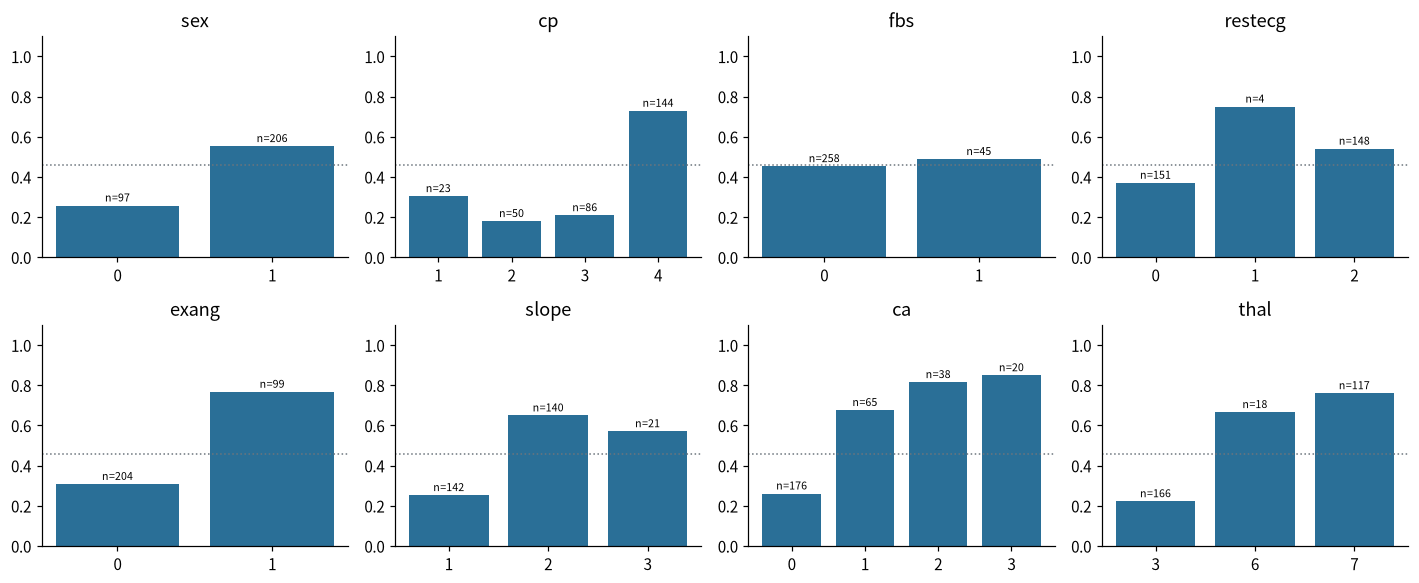

In [5]:
fig, ax = plt.subplots(2, 4, figsize=(13, 5.4))
for a, v in zip(ax.ravel(), CAT):
    g = df.groupby(v).target.agg(["mean", "size"]); a.bar(g.index.astype(int).astype(str), g["mean"], color=BLUE)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])): a.text(i, m + .02, f"n={n}", ha="center", fontsize=7)
    a.set(title=v, ylim=(0, 1.1)); a.axhline(df.target.mean(), color=GREY, ls=":", lw=1)
save("fig_eda_categorical.png")

### 2.4 Correlations and the age–heart-rate relationship

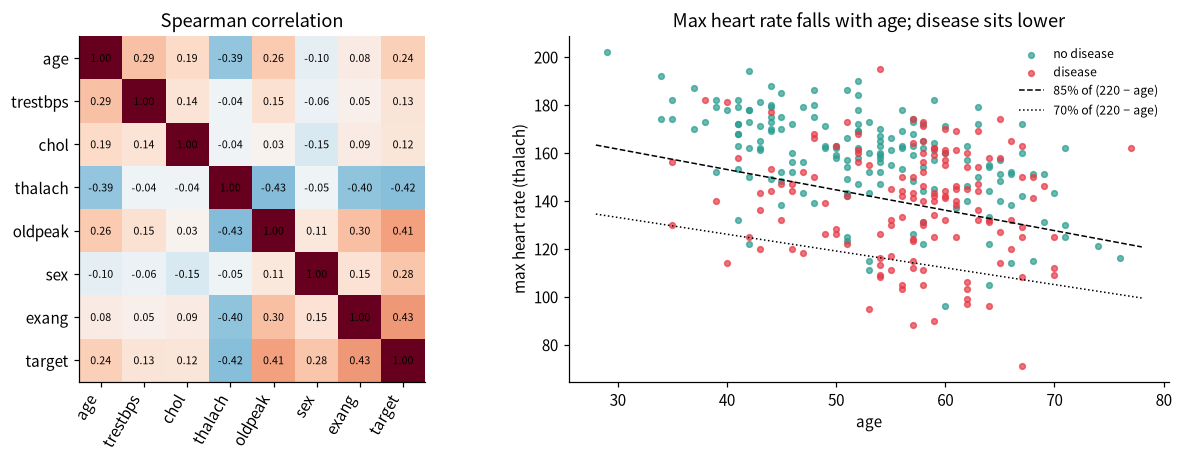

In [6]:
cm = df[NUM + ["sex", "exang", "target"]].corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(11.5, 4.3), gridspec_kw={"width_ratios": [1, 1.1]})
im = ax[0].imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1); ax[0].set_xticks(range(len(cm))); ax[0].set_xticklabels(cm.columns, rotation=60, ha="right"); ax[0].set_yticks(range(len(cm))); ax[0].set_yticklabels(cm.columns)
for i in range(len(cm)):
    for j in range(len(cm)): ax[0].text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax[0].set_title("Spearman correlation")
for t, c, l in [(0, NEG, "no disease"), (1, POS, "disease")]: ax[1].scatter(df.age[df.target == t], df.thalach[df.target == t], s=14, c=c, alpha=.7, label=l)
xs = np.linspace(28, 78, 50)
for pct, ls in [(.85, "--"), (.70, ":")]: ax[1].plot(xs, pct * (220 - xs), "k", ls=ls, lw=1, label=f"{pct:.0%} of (220 − age)")
ax[1].set(xlabel="age", ylabel="max heart rate (thalach)", title="Max heart rate falls with age; disease sits lower"); ax[1].legend(frameon=False, fontsize=8)
save("fig_eda_corr_hr.png")

### 2.5 Which variables carry univariate signal? (exploratory only)
Computed on the full data purely to *understand* the data. It is **not** used for feature selection or model choice (that would leak).

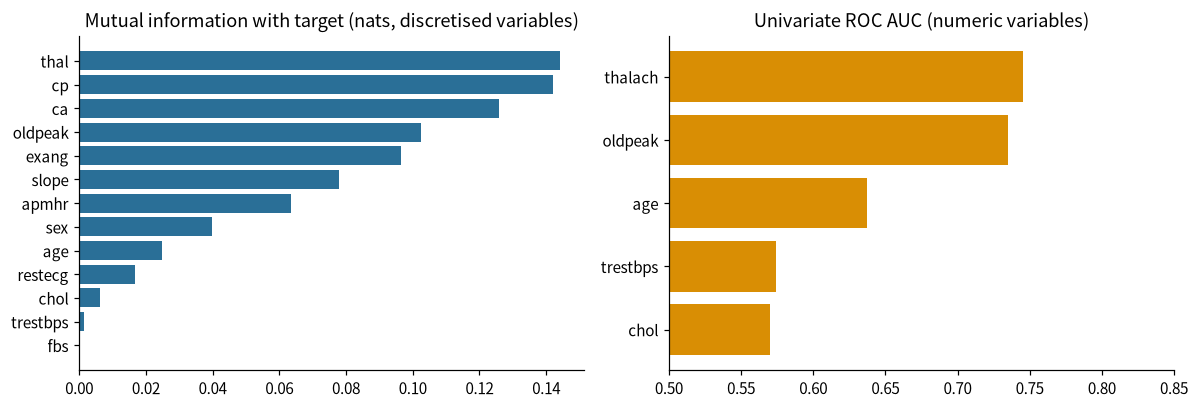

top-5 MI: {'thal': 0.144, 'cp': 0.142, 'ca': 0.126, 'oldpeak': 0.102, 'exang': 0.096}


In [7]:
Xd_full = discretize(df); mi = {}
for v in DISC_FEATURES: mi[v] = mutual_info_score(Xd_full[v].fillna(-1).astype(str), df.target)
auc_num = {v: max(roc_auc_score(df.target, df[v]), 1 - roc_auc_score(df.target, df[v])) for v in NUM}
mi = pd.Series(mi).sort_values(); fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].barh(mi.index, mi.values, color=BLUE); ax[0].set(title="Mutual information with target (nats, discretised variables)")
a = pd.Series(auc_num).sort_values(); ax[1].barh(a.index, a.values, color=AMBER); ax[1].set(title="Univariate ROC AUC (numeric variables)", xlim=(.5, .85))
save("fig_eda_signal.png"); print("top-5 MI:", mi.sort_values(ascending=False).head(5).round(3).to_dict())

### 2.6 EDA takeaways
The displayed charts describe this small, historical dataset. Work-up variables such as `ca` and `thal` have strong associations with the existing diagnosis. Associations are not causal effects. The supplied graph and HR transformation are motivated partly by EDA; this is an exploratory project, not a preregistered confirmatory evaluation.

## 3. Preprocessing and discretisation
Cut points are constants in the supplied code, not fit on validation data. They are modelling choices and not diagnostic criteria. Bins are right-open `[a,b)` with infinite outer boundaries. The age-predicted HR expression is a rough feature transformation, not a test for chronotropic incompetence.

,variable,states,interior cut points,rationale
0,age,<50 | 50-59 | >=60,"50, 60",decade-style risk bands
1,trestbps,<130 | >=130,130,fixed modelling split at 130 mmHg; not a diagn...
2,chol,<240 | >=240,240,fixed modelling split at 240 mg/dl
3,apmhr,<70% | 70-84% | >=85%,"0.7, 0.85",rough age-adjusted HR feature; not a diagnosti...
4,oldpeak,<1mm | 1-<2mm | >=2mm,"1, 2",fixed splits at 1 and 2 in supplied ST-depress...


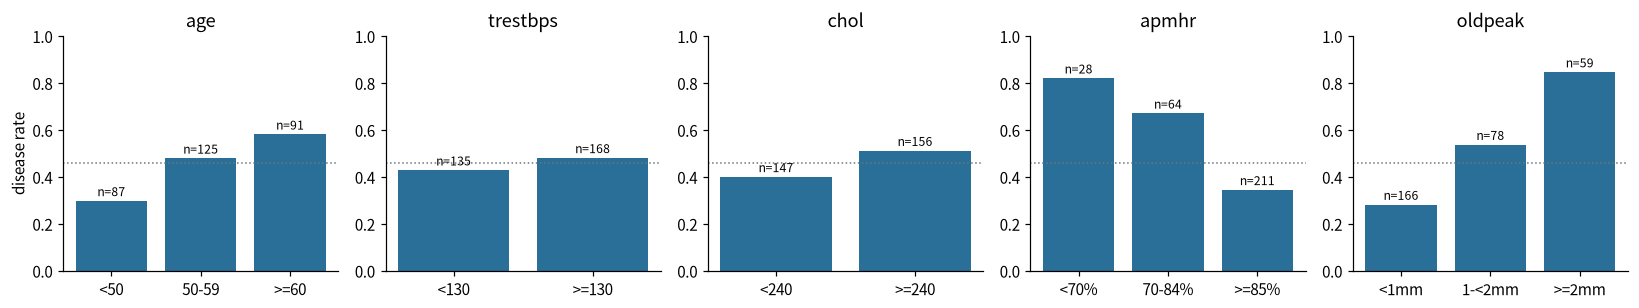

In [8]:
cp = cutpoint_table(); cp["rationale"] = ["decade-style risk bands", "fixed modelling split at 130 mmHg; not a diagnosis", "fixed modelling split at 240 mg/dl",
  "rough age-adjusted HR feature; not a diagnostic criterion", "fixed splits at 1 and 2 in supplied ST-depression units"]
display(cp); cp.to_csv(RES / "phase1_cutpoints.csv", index=False)
fig, ax = plt.subplots(1, 5, figsize=(15, 2.9)); rows = []
for a, v in zip(ax, DISC_NUM):
    g = pd.DataFrame({"bin": Xd_full[v], "y": df.target}).groupby("bin").y.agg(["mean", "size"]).reindex(STATES[v])
    a.bar(g.index, g["mean"], color=BLUE); a.set(title=v, ylim=(0, 1)); a.axhline(df.target.mean(), color=GREY, ls=":", lw=1)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])): a.text(i, m + .02, f"n={n}", ha="center", fontsize=8)
ax[0].set_ylabel("disease rate"); save("fig_bin_rates.png")

**Reading the bin plots.** The bars show full-dataset associations and small-bin counts. They do not prove these cut points are optimal or clinically valid. No cut-point search was performed during this audit.

**Leakage safeguards:** training-fold imputation and scaling; identical held-out row indices; fixed model settings; missing evidence omitted for BN inference; threshold 0.5 not selected from validation outcomes. Full-data EDA informed some design choices in the supplied work, so model-selection optimism remains possible. We cannot establish that the original choices were made before seeing results.

## 4. Models

### 4.1 Hand-specified Bayesian network
The graph encodes assumed dependencies: risk factors -> target -> findings, plus age -> blood pressure and two within-finding edges. These arrows are modelling assumptions, not established causal relationships. BDeu smoothing uses equivalent sample size 5. Naive Bayes uses a target-centred star with the same discretisation and estimator.

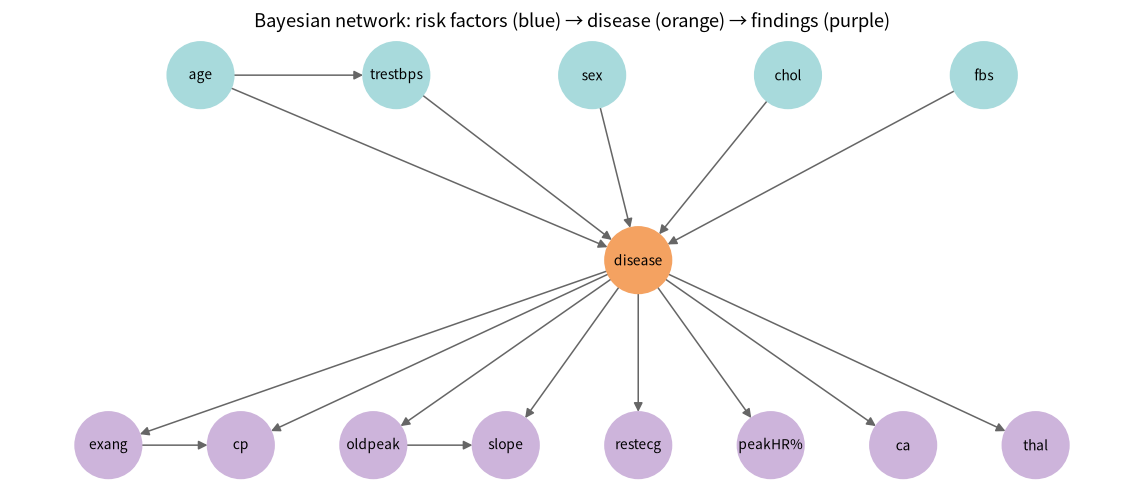

edges: 16 | parents of disease: ['age', 'sex', 'trestbps', 'chol', 'fbs']


In [9]:
G = nx.DiGraph(BN_EDGES); top = ["age", "trestbps", "sex", "chol", "fbs"]; bot = ["exang", "cp", "oldpeak", "slope", "restecg", "apmhr", "ca", "thal"]
pos = {n: (1.7 * i + .8, 3) for i, n in enumerate(top)}; pos.update({n: (1.15 * i, 0) for i, n in enumerate(bot)}); pos[Y] = (4.6, 1.5)
fig, ax = plt.subplots(figsize=(10.5, 4.6))
nx.draw_networkx(G, pos, ax=ax, node_color=["#f4a261" if n == Y else "#a8dadc" if pos[n][1] == 3 else "#cdb4db" for n in G.nodes], node_size=1900, font_size=9,
                 arrowsize=12, edge_color="#666", labels={n: ("disease" if n == Y else "peakHR%" if n == "apmhr" else n) for n in G.nodes})
ax.axis("off"); ax.set_title("Bayesian network: risk factors (blue) → disease (orange) → findings (purple)"); save("fig_bn_structure.png")
print("edges:", len(BN_EDGES), "| parents of disease:", [a for a, b in BN_EDGES if b == Y])

**Illustrative full-data CPD only:** this fit explains the table format and is never used to generate validation predictions.

In [10]:
bn_full = BNClassifier(BN_EDGES).fit(Xd_full, df.target.values)
cpd = bn_full.model.get_cpds("ca"); print("P(ca | disease)  [columns: no disease, disease]"); print(pd.DataFrame(cpd.values, index=[f"ca={s}" for s in cpd.state_names["ca"]], columns=["no disease", "disease"]).round(3))
cpd = bn_full.model.get_cpds(Y); print("\nDisease node: %d parents -> %d parent configurations for ~%d training rows per fold" % (len(bn_full.model.get_parents(Y)), cpd.values.shape[1:].__len__() and int(np.prod(cpd.values.shape[1:])), int(.8 * len(df))))

P(ca | disease)  [columns: no disease, disease]
      no disease  disease
ca=0       0.799    0.332
ca=1       0.132    0.318
ca=2       0.047    0.225
ca=3       0.022    0.125

Disease node: 5 parents -> 48 parent configurations for ~242 training rows per fold


### 4.2 Classical reference models
Prior-only, discrete Naive Bayes, structured BN, L2 logistic regression on binned or continuous data, and random forest. Logistic regression uses C=0.5. The forest uses 300 trees and minimum leaf size 3. Settings were retained from the supplied project, not tuned during the audit. A matched continuous age-adjusted-HR logistic control is added below to separate representation changes from binning.

## 5. Evaluation protocol
Repeated stratified 5-fold CV, 5 repeats, split seed 2026. Every model uses the same splits. Each patient row is held out once per repeat. Metrics are computed separately per repeat, then averaged. PR AUC here means scikit-learn **average precision (AP)**, not trapezoidal PR area. Sensitivity/specificity use threshold 0.5. Calibration: Brier, ECE (10 equal-frequency bins), slope/intercept. Bootstrap intervals resample patient indices shared across repeats (500 draws) and condition on the fitted OOF predictions; they do not include full training variability. Corrected t-tests are exploratory AUC comparisons, not equivalence tests or multiplicity-controlled confirmatory findings. Forest seeds are split indices 0..24, not 2026 for every fit.

In [11]:
y = df.target.values; Xr = df[FEATURES]; Xd = discretize(df)
splits = list(RepeatedStratifiedKFold(n_splits=K, n_repeats=R, random_state=SEED).split(Xr, y))
NO_TEST = [f for f in FEATURES if f not in ("ca", "thal")]; NO_TEST_D = [f for f in DISC_FEATURES if f not in ("ca", "thal")]
MODELS = {"Prior only": (lambda s: Prior(), Xr), "Naive Bayes": (lambda s: BNClassifier(NB_EDGES), Xd), "Bayesian net": (lambda s: BNClassifier(BN_EDGES), Xd),
          "LogReg (disc.)": (lambda s: LogReg("discretized"), Xd), "LogReg (cont.)": (lambda s: LogReg("continuous"), Xr), "Random forest": (lambda s: Forest(seed=s), Xr)}
results = {}
for name, (mk, X) in MODELS.items():
    t = time.time(); results[name] = run_cv(mk, X, y, splits, K)
    print(f"{name:<16} mean ROC AUC over repeats = {np.mean([roc_auc_score(y, o) for o in results[name]['oof']]):.3f}  ({time.time()-t:.0f}s)")
pd.concat([pd.DataFrame({"model": n, "repeat": r, "patient": np.arange(len(y)), "y": y, "p": d["oof"][r]}) for n, d in results.items() for r in range(R)]).to_csv(RES / "phase1_oof_predictions.csv.gz", index=False)
manifest = pd.concat([pd.DataFrame({"split": s, "repeat": s//K, "fold": s%K, "patient": te}) for s, (_, te) in enumerate(splits)])
manifest.to_csv(RES / "cv_test_assignments.csv", index=False)


Prior only       mean ROC AUC over repeats = 0.495  (0s)


Naive Bayes      mean ROC AUC over repeats = 0.908  (3s)


Bayesian net     mean ROC AUC over repeats = 0.896  (3s)


LogReg (disc.)   mean ROC AUC over repeats = 0.907  (0s)


LogReg (cont.)   mean ROC AUC over repeats = 0.911  (1s)


Random forest    mean ROC AUC over repeats = 0.908  (10s)


## 6. Results

In [12]:
M, bv = summarize(results, y, B=B, seed=SEED); M.to_csv(RES / "phase1_metrics.csv", index=False)
show = M.copy(); show["ROC AUC [95% CI]"] = show.apply(lambda r: f"{r['ROC AUC']:.3f} [{r['ROC AUC lo']:.3f}, {r['ROC AUC hi']:.3f}]" if pd.notna(r.get("ROC AUC lo")) else "0.500", axis=1)
show["PR AUC [95% CI]"] = show.apply(lambda r: f"{r['PR AUC']:.3f} [{r['PR AUC lo']:.3f}, {r['PR AUC hi']:.3f}]" if pd.notna(r.get("PR AUC lo")) else f"{r['PR AUC']:.3f}", axis=1)
display(show[["model", "ROC AUC [95% CI]", "PR AUC [95% CI]", "Sensitivity", "Specificity", "Brier", "ECE", "Cal. slope", "Cal. intercept"]].round(3).set_index("model"))

,ROC AUC [95% CI],PR AUC [95% CI],Sensitivity,Specificity,Brier,ECE,Cal. slope,Cal. intercept
model,,,,,,,,
Prior only,0.500,0.456,0.000,1.000,0.248,0.052,NaN,NaN
Naive Bayes,"0.908 [0.874, 0.939]","0.904 [0.858, 0.940]",0.791,0.888,0.126,0.087,0.511,-0.006
Bayesian net,"0.896 [0.861, 0.927]","0.882 [0.833, 0.926]",0.778,0.851,0.139,0.086,0.487,-0.037
LogReg (disc.),"0.907 [0.870, 0.938]","0.898 [0.845, 0.938]",0.809,0.888,0.118,0.050,0.987,0.023
LogReg (cont.),"0.911 [0.875, 0.941]","0.905 [0.858, 0.941]",0.804,0.889,0.116,0.047,0.983,0.008
Random forest,"0.908 [0.869, 0.938]","0.901 [0.858, 0.937]",0.787,0.855,0.125,0.055,1.421,0.074


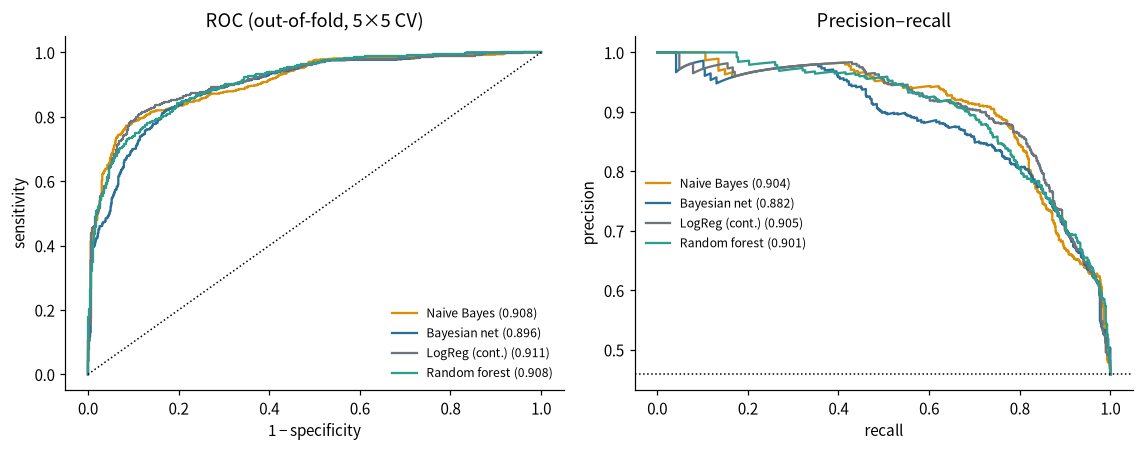

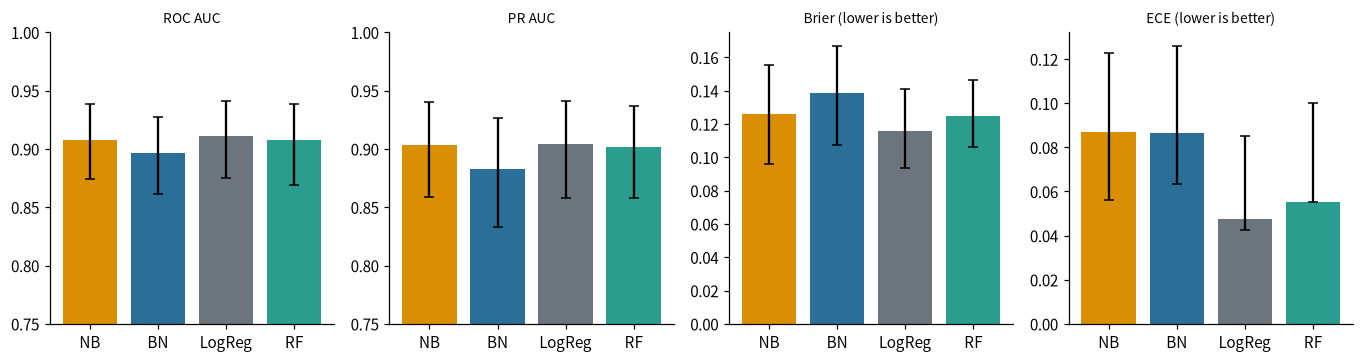

In [13]:
COL = {"Naive Bayes": AMBER, "Bayesian net": BLUE, "LogReg (cont.)": GREY, "LogReg (disc.)": "#adb5bd", "Random forest": "#2a9d8f"}; SHOW = ["Naive Bayes", "Bayesian net", "LogReg (cont.)", "Random forest"]
pool = lambda m: (np.tile(y, R), results[m]["oof"].ravel())
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.2)); Mi = M.set_index("model")
for m in SHOW:
    yy, pp = pool(m); f, t, _ = roc_curve(yy, pp); ax[0].plot(f, t, color=COL[m], label=f"{m} ({Mi.loc[m, 'ROC AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(yy, pp); ax[1].plot(rc, pr, color=COL[m], label=f"{m} ({Mi.loc[m, 'PR AUC']:.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set(xlabel="1 − specificity", ylabel="sensitivity", title="ROC (out-of-fold, 5×5 CV)"); ax[1].axhline(y.mean(), color="k", ls=":", lw=1); ax[1].set(xlabel="recall", ylabel="precision", title="Precision–recall")
for a in ax: a.legend(frameon=False, fontsize=8)
save("fig_roc_pr.png")
fig, ax = plt.subplots(1, 4, figsize=(12.5, 3.4))
for a, k in zip(ax, ["ROC AUC", "PR AUC", "Brier", "ECE"]):
    d = Mi.loc[SHOW]; a.bar(range(4), d[k], color=[COL[m] for m in SHOW], yerr=[(d[k] - d[k + " lo"]).clip(lower=0), (d[k + " hi"] - d[k]).clip(lower=0)], capsize=3)
    a.set_xticks(range(4)); a.set_xticklabels(["NB", "BN", "LogReg", "RF"]); a.set_title(k + (" (lower is better)" if k in ("Brier", "ECE") else ""), fontsize=9)
    if "AUC" in k: a.set_ylim(.75, 1)
save("fig_metrics.png")

### 6.1 Calibration
A fitted calibration slope below one is consistent with over-extreme probabilities; above one with compressed probabilities. Intercept and curve shape also matter. Calibration regressions are diagnostics on OOF predictions, not a trained recalibration procedure. ECE depends on binning and is unstable at this sample size. Pooled-repeat curves are descriptive only: 1,515 predictions still come from 303 rows.

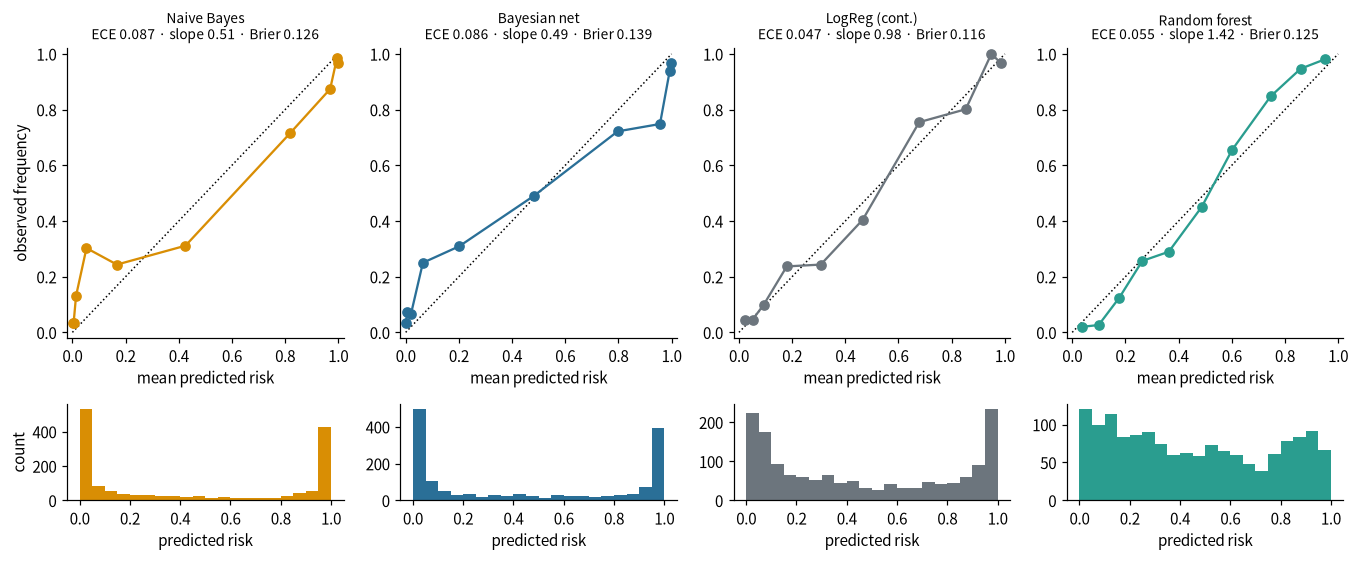

In [14]:
fig, ax = plt.subplots(2, 4, figsize=(12.5, 5.2), gridspec_kw={"height_ratios": [3, 1]})
for j, m in enumerate(SHOW):
    yy, pp = pool(m); ch = np.array_split(np.argsort(pp), 10)
    ax[0, j].plot([0, 1], [0, 1], "k:", lw=1); ax[0, j].plot([pp[c].mean() for c in ch], [yy[c].mean() for c in ch], "o-", color=COL[m])
    ax[0, j].set(title=f"{m}\nECE {Mi.loc[m,'ECE']:.3f} · slope {Mi.loc[m,'Cal. slope']:.2f} · Brier {Mi.loc[m,'Brier']:.3f}", xlim=(-.02, 1.02), ylim=(-.02, 1.02), xlabel="mean predicted risk", ylabel="observed frequency" if j == 0 else "")
    ax[0, j].title.set_fontsize(9); ax[1, j].hist(pp, bins=20, range=(0, 1), color=COL[m]); ax[1, j].set(xlabel="predicted risk", ylabel="count" if j == 0 else "")
save("fig_calibration.png")

### 6.2 Exploratory paired comparisons
Point differences use the original OOF metric difference. Intervals use paired patient bootstrap draws. Do not call non-significant differences a statistical tie or claim model equivalence.

In [15]:
pairs = [("Bayesian net", "Naive Bayes"), ("Bayesian net", "LogReg (disc.)"), ("Naive Bayes", "LogReg (cont.)"), ("Bayesian net", "LogReg (cont.)"), ("Random forest", "LogReg (cont.)"),
         ("Random forest", "Bayesian net"), ("LogReg (disc.)", "LogReg (cont.)")]
PC = paired(results, bv, pairs, K, y=y); PC.to_csv(RES / "phase1_paired.csv", index=False); display(PC.round(3))

,A,B,metric,mean diff (A-B),lo,hi,corrected t,corrected p
0,Bayesian net,Naive Bayes,ROC AUC,-0.012,-0.026,0.005,-1.553,0.133
1,Bayesian net,Naive Bayes,PR AUC,-0.021,-0.036,-0.006,NaN,NaN
2,Bayesian net,Naive Bayes,Brier,0.013,-0.002,0.025,NaN,NaN
3,Bayesian net,LogReg (disc.),ROC AUC,-0.011,-0.028,0.010,-1.251,0.223
4,Bayesian net,LogReg (disc.),PR AUC,-0.016,-0.035,0.004,NaN,NaN
5,Bayesian net,LogReg (disc.),Brier,0.021,0.005,0.035,NaN,NaN
6,Naive Bayes,LogReg (cont.),ROC AUC,-0.003,-0.017,0.010,-0.585,0.564
7,Naive Bayes,LogReg (cont.),PR AUC,-0.001,-0.014,0.012,NaN,NaN
8,Naive Bayes,LogReg (cont.),Brier,0.010,-0.002,0.025,NaN,NaN
9,Bayesian net,LogReg (cont.),ROC AUC,-0.015,-0.033,0.005,-1.420,0.168


### 6.3 Interpretation of the measured results
Use the tables above as the source of truth. Ranking performance is numerically close, with no statistically detectable AUC difference in the reported exploratory comparisons; equivalence is not established. The BN did not outperform Naive Bayes on this configuration. Logistic regression has lower Brier loss and calibration slope nearer one in these OOF predictions. Brier reflects overall probability quality, not calibration alone. A causal mechanism for Bayesian overconfidence has not been established.

## 7. Ablations and sensitivity

### 7.1 Binning and the missing control
The original continuous model uses raw `thalach`, whereas the binned models use `thalach/(220-age)`. Comparing those two alone mixes representation and binning. The next control uses continuous age-adjusted HR and identical remaining features. Compare binned logistic regression against this matched continuous model; retain raw-HR logistic regression as the project baseline.

In [16]:
Xa = add_age_adjusted_hr(Xr)
matched = run_cv(lambda s: LogReg("matched_continuous"), Xa, y, splits, K)
control_results = {"LogReg (disc.)": results["LogReg (disc.)"], "LogReg (matched HR)": matched}
MC, bvc = summarize(control_results, y, B=B, seed=SEED)
MC.to_csv(RES / "phase1_matched_hr.csv", index=False)
matched_pair = paired(control_results, bvc, [("LogReg (disc.)", "LogReg (matched HR)")], K, y=y)
matched_pair.to_csv(RES / "phase1_matched_hr_paired.csv", index=False)
display(MC.round(4)); display(matched_pair.round(4))
pd.concat([pd.DataFrame({"repeat": r, "patient": np.arange(len(y)), "y": y, "p": matched["oof"][r]}) for r in range(R)]).to_csv(RES / "phase1_matched_hr_oof.csv.gz", index=False)


,model,ROC AUC,PR AUC,Sensitivity,Specificity,Brier,ECE,Log loss,Cal. slope,Cal. intercept,ROC AUC lo,ROC AUC hi,PR AUC lo,PR AUC hi,Sensitivity lo,Sensitivity hi,Specificity lo,Specificity hi,Brier lo,Brier hi,ECE lo,ECE hi
0,LogReg (disc.),0.9068,0.8984,0.8086,0.8878,0.1177,0.0505,0.3802,0.9874,0.0228,0.8697,0.9376,0.8452,0.9383,0.7404,0.8677,0.8446,0.9314,0.0955,0.1443,0.0445,0.0898
1,LogReg (matched HR),0.9106,0.9044,0.8029,0.8878,0.1160,0.0434,0.3737,0.9833,0.0080,0.8750,0.9409,0.8575,0.9409,0.7405,0.8594,0.8408,0.9293,0.0935,0.1411,0.0412,0.0840


,A,B,metric,mean diff (A-B),lo,hi,corrected t,corrected p
0,LogReg (disc.),LogReg (matched HR),ROC AUC,-0.0038,-0.0125,0.0043,-0.5054,0.6179
1,LogReg (disc.),LogReg (matched HR),PR AUC,-0.0060,-0.0175,0.0045,NaN,NaN
2,LogReg (disc.),LogReg (matched HR),Brier,0.0016,-0.0042,0.0076,NaN,NaN


### 7.2 Drop `ca` and `thal`
This removes two diagnostic work-up variables, not all exercise-test information. The resulting model still predicts existing disease status, not future incident heart-disease risk.

In [17]:
MODELS_B = {"Naive Bayes": (lambda s: BNClassifier(NB_EDGES, features=NO_TEST_D), Xd), "Bayesian net": (lambda s: BNClassifier(BN_EDGES, features=NO_TEST_D), Xd),
            "LogReg (cont.)": (lambda s: LogReg("continuous", NO_TEST), Xr), "Random forest": (lambda s: Forest(NO_TEST, seed=s), Xr)}
resB = {n: run_cv(mk, X, y, splits, K) for n, (mk, X) in MODELS_B.items()}; MB, _ = summarize(resB, y, B=B, seed=SEED); MB.to_csv(RES / "phase1_scenarioB.csv", index=False)
cmp = MB.set_index("model")[["ROC AUC", "ROC AUC lo", "ROC AUC hi", "PR AUC", "Brier", "ECE", "Cal. slope"]].round(3); cmp["ΔAUC vs all 13"] = (MB.set_index("model")["ROC AUC"] - Mi["ROC AUC"]).round(3); display(cmp)

,ROC AUC,ROC AUC lo,ROC AUC hi,PR AUC,Brier,ECE,Cal. slope,ΔAUC vs all 13
model,,,,,,,,
Naive Bayes,0.866,0.825,0.906,0.858,0.158,0.108,0.524,-0.042
Bayesian net,0.846,0.805,0.884,0.815,0.170,0.107,0.488,-0.050
LogReg (cont.),0.872,0.830,0.909,0.860,0.144,0.046,0.945,-0.039
Random forest,0.862,0.820,0.900,0.852,0.151,0.061,1.209,-0.046


### 7.3 Prior-strength sensitivity
BDeu ESS 1, 5 and 20 are robustness checks. ESS 5 remains the supplied headline setting; do not select the best ESS from these validation results and report it as an unbiased winner.

,ROC AUC,PR AUC,Brier,ECE,Cal. slope
variant,,,,,
BN ess=1,0.883,0.865,0.153,0.103,0.411
NB ess=1,0.907,0.902,0.128,0.088,0.494
BN ess=5,0.896,0.882,0.139,0.086,0.487
NB ess=5,0.908,0.904,0.126,0.087,0.511
BN ess=20,0.905,0.893,0.128,0.070,0.576
NB ess=20,0.909,0.906,0.123,0.080,0.559


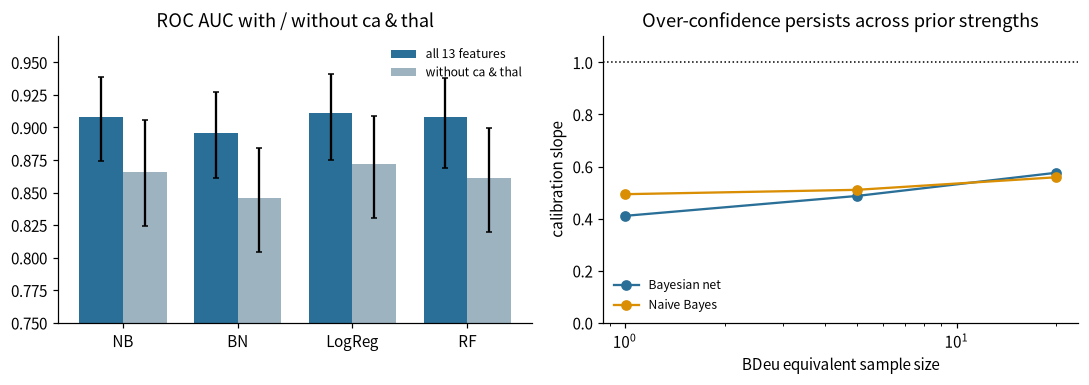

In [18]:
sens = {}
for e in (1, 5, 20):
    sens[f"BN ess={e}"] = run_cv(lambda s, e=e: BNClassifier(BN_EDGES, ess=e), Xd, y, splits, K); sens[f"NB ess={e}"] = run_cv(lambda s, e=e: BNClassifier(NB_EDGES, ess=e), Xd, y, splits, K)
S = pd.DataFrame([{"variant": n, **mean_metrics(y, d["oof"], full=True)[["ROC AUC", "PR AUC", "Brier", "ECE", "Cal. slope"]].to_dict()} for n, d in sens.items()]).set_index("variant")
S.to_csv(RES / "phase1_sensitivity.csv"); display(S.round(3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6)); w = .38
for i, (sc, lab, col) in enumerate([("A", "all 13 features", BLUE), ("B", "without ca & thal", "#9db4c0")]):
    d = (Mi if sc == "A" else MB.set_index("model")).loc[SHOW]; ax[0].bar(np.arange(4) + (i - .5) * w, d["ROC AUC"], w, label=lab, color=col, yerr=[(d["ROC AUC"] - d["ROC AUC lo"]).clip(lower=0), (d["ROC AUC hi"] - d["ROC AUC"]).clip(lower=0)], capsize=2)
ax[0].set_xticks(range(4)); ax[0].set_xticklabels(["NB", "BN", "LogReg", "RF"]); ax[0].set(ylim=(.75, .97), title="ROC AUC with / without ca & thal"); ax[0].legend(frameon=False, fontsize=8)
e = [1, 5, 20]; ax[1].plot(e, [S.loc[f"BN ess={k}", "Cal. slope"] for k in e], "o-", color=BLUE, label="Bayesian net"); ax[1].plot(e, [S.loc[f"NB ess={k}", "Cal. slope"] for k in e], "o-", color=AMBER, label="Naive Bayes")
ax[1].axhline(1, color="k", ls=":", lw=1); ax[1].set(xscale="log", xlabel="BDeu equivalent sample size", ylabel="calibration slope", ylim=(0, 1.1), title="Over-confidence persists across prior strengths"); ax[1].legend(frameon=False, fontsize=8)
save("fig_ablation.png")

## 8. BN explanation with complete evidence
For a fully observed predictor row, posterior log-odds equal the target-parent logit plus a log-likelihood-ratio term for each target child (with other parents conditioned on). This explains the specified model, not physiology. Missing-evidence predictions still use exact variable elimination, but the simple additive function intentionally rejects incomplete rows. Global explanation summaries therefore use complete-evidence rows only.

max |decomposition − pgmpy variable elimination| over 297 patients = 2.2e-16


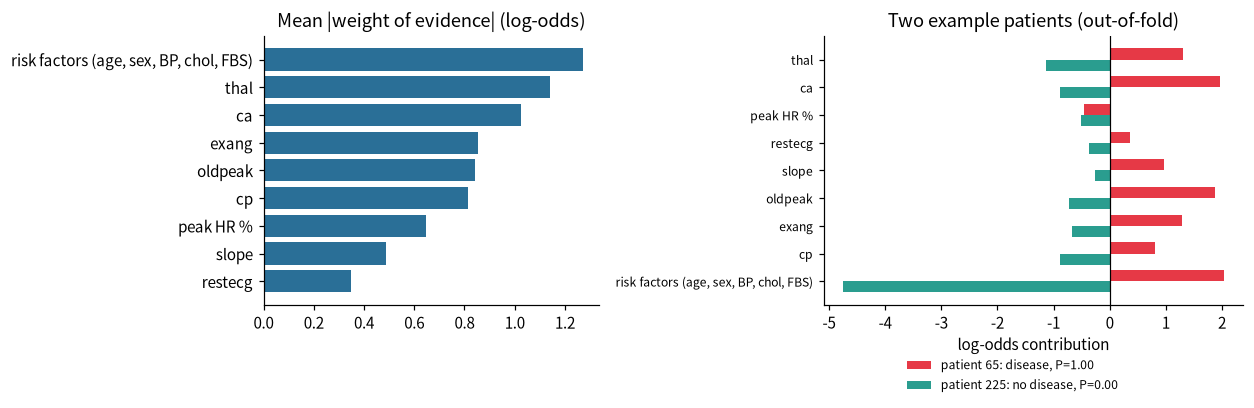

Largest false alarm: patient 252 (no disease) predicted P=1.00; risk-factor term +1.37, strongest other terms: {'peak HR %': 1.9, 'exang': 1.25, 'thal': 1.22}
Complete-evidence explanation rows: 297


In [19]:
chk = [abs(1 / (1 + np.exp(-sum(bn_full.contributions(Xd_full.iloc[i]).values()))) - bn_full.predict_proba_one(Xd_full.iloc[i])) for i in range(len(df)) if Xd_full.iloc[i].notna().all()]
print(f"max |decomposition − pgmpy variable elimination| over {len(chk)} patients = {max(chk):.1e}")
rows, pbn = [None] * len(y), np.zeros(len(y))
for s, (tr, te) in enumerate(splits[:K]):
    m = BNClassifier(BN_EDGES).fit(Xd.iloc[tr], y[tr]); pbn[te] = m.predict_proba(Xd.iloc[te])
    for i in te:
        if Xd.iloc[i].notna().all(): rows[i] = m.contributions(Xd.iloc[i])
        else: rows[i] = {}
W = pd.DataFrame(rows).rename(columns={"apmhr": "peak HR %", "risk-factor prior": "risk factors (age, sex, BP, chol, FBS)"})
imp = W.abs().mean().sort_values(); fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9), gridspec_kw={"width_ratios": [1, 1.25]})
ax[0].barh(imp.index, imp.values, color=BLUE); ax[0].set(title="Mean |weight of evidence| (log-odds)")
ex = [int(np.argmax(np.where(y == 1, pbn, -1))), int(np.argmin(np.where(y == 0, pbn, 2)))]; yv = np.arange(W.shape[1])
ax[1].barh(yv + .2, W.iloc[ex[0]], .4, color=POS, label=f"patient {ex[0]}: disease, P={pbn[ex[0]]:.2f}"); ax[1].barh(yv - .2, W.iloc[ex[1]], .4, color=NEG, label=f"patient {ex[1]}: no disease, P={pbn[ex[1]]:.2f}")
ax[1].set_yticks(yv); ax[1].set_yticklabels(W.columns, fontsize=8); ax[1].axvline(0, color="k", lw=.8); ax[1].legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.45, -0.16), ncol=1); ax[1].set(title="Two example patients (out-of-fold)", xlabel="log-odds contribution")
save("fig_bn_weights.png"); W.to_csv(RES / "phase1_bn_weights.csv", index=False)
bad = int(np.argmax(np.where(y == 0, pbn, -1))); print(f"Largest false alarm: patient {bad} (no disease) predicted P={pbn[bad]:.2f}; risk-factor term {W.iloc[bad].iloc[0]:+.2f}, strongest other terms:", W.iloc[bad].drop(W.columns[0]).sort_values(key=abs, ascending=False).head(3).round(2).to_dict())
print("Complete-evidence explanation rows:", int(W.notna().all(axis=1).sum()))


### 8.1 Interpretation limits
Numerical agreement is checked against exact inference on complete rows. Findings can accumulate under the graph assumptions; dependence misspecification and sparse CPDs are plausible explanations for extreme predictions, not demonstrated causes. Rounding a posterior to 1.00 is not certainty.

## 9. Findings, gap analysis, limitations and hand-off to Phase 2

### 9.1 Main conclusions and Phase 2 boundary
The original primary-model predictions were independently reproduced. Phase 1 compares interpretable probabilistic and classical models; it does not prove equivalence, a causal explanation for calibration, or a universal lack of nonlinear interactions. The matched-HR control repairs the binning comparison. Phase 2 remains future work: a regularised MLP and optional SHAP on the same saved split indices. Do not treat these baseline-seen folds as a new untouched test set; reserve external data or a genuinely untouched assessment if feasible.

In [20]:
base = Mi.loc[["Naive Bayes", "Bayesian net", "LogReg (disc.)", "LogReg (cont.)", "Random forest"], ["ROC AUC", "PR AUC", "Sensitivity", "Specificity", "Brier", "ECE", "Cal. slope"]].round(3)
base.to_csv(RES / "phase1_baselines_for_phase2.csv"); print("Phase 1 baseline table the Phase 2 MLP must be compared against (same 25 splits, seed 2026):"); display(base)

Phase 1 baseline table the Phase 2 MLP must be compared against (same 25 splits, seed 2026):


,ROC AUC,PR AUC,Sensitivity,Specificity,Brier,ECE,Cal. slope
model,,,,,,,
Naive Bayes,0.908,0.904,0.791,0.888,0.126,0.087,0.511
Bayesian net,0.896,0.882,0.778,0.851,0.139,0.086,0.487
LogReg (disc.),0.907,0.898,0.809,0.888,0.118,0.050,0.987
LogReg (cont.),0.911,0.905,0.804,0.889,0.116,0.047,0.983
Random forest,0.908,0.901,0.787,0.855,0.125,0.055,1.421


### 9.2 Limitations
303 historical Cleveland rows, mostly male; no external validation or verifiable patient IDs in this processed file. Existing angiographic disease status is not a future event. Even without ca/thal the inputs include exercise-test findings. Graph, bins and supplied hyperparameters were not preregistered or tuned under nested CV. EDA-informed choices can induce optimism. Fixed-prediction bootstrap intervals omit training variability; ECE and calibration slope are noisy; repeated predictions are dependent. Diagnostic performance is not clinical utility. This is a course prediction exercise only.